# Machine Learning No Supervisado: Clustering y Reducción de Dimensionalidad

**Autor:** Juan Camilo Cruz Beltrán  
**Especialización en Inteligencia Artificial**

En este notebook se aplican:
1. **Clustering:** K-means y Clustering Jerárquico (aglomerativo).
2. **Reducción de dimensionalidad:** PCA y SVD.

Dataset: *Wine* (Scikit-Learn), con 178 vinos descritos por 13 variables químicas y 3 cultivares. Las etiquetas **no** se usan para entrenar; solo se usan al final para validar qué tan bien los algoritmos recuperaron la estructura real.

## 1. Preparación de los datos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

os.makedirs('figuras', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_real = wine.target          # solo para validar al final, NO para entrenar

print('Dimensiones:', X.shape)
X.head()

Dimensiones: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [2]:
# Estadísticos descriptivos: las variables tienen escalas muy distintas
X.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


**Estandarización.** K-means, el clustering jerárquico y PCA dependen de distancias/varianzas. Si una variable (p. ej. *proline*, en cientos) tiene una escala mucho mayor que otra (p. ej. *hue*, cercana a 1), dominaría el resultado. Por eso se estandariza cada variable a media 0 y desviación estándar 1.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Media por variable (≈0):', X_scaled.mean(axis=0).round(2)[:4], '...')
print('Desv. estándar (≈1):  ', X_scaled.std(axis=0).round(2)[:4], '...')

Media por variable (≈0): [-0. -0. -0. -0.] ...
Desv. estándar (≈1):   [1. 1. 1. 1.] ...


## 2. Clustering con K-means

### 2.1 Elección del número de clusters (k)
Se usan dos criterios: el **método del codo** (inercia: suma de distancias al cuadrado al centroide) y el **coeficiente de silueta** (mide cohesión y separación; va de -1 a 1, más alto es mejor).

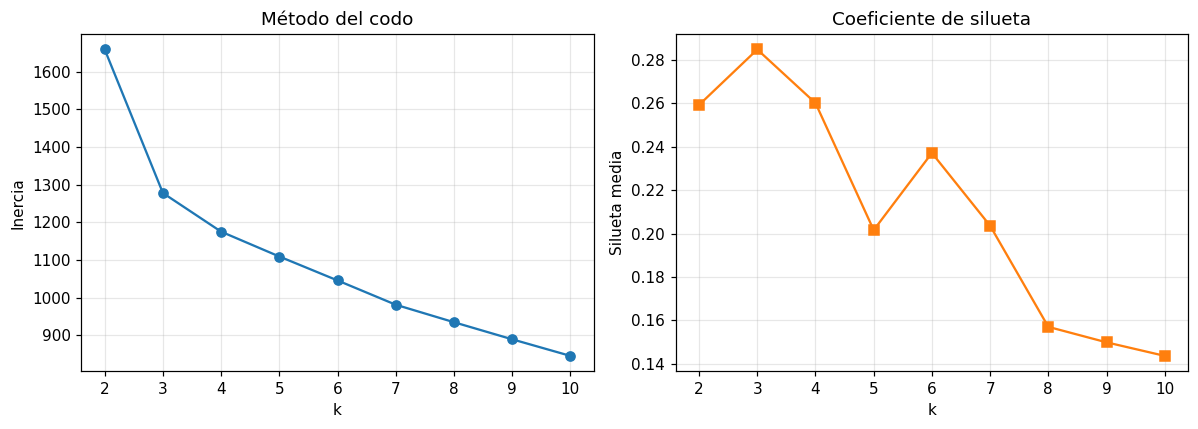

k=2: silueta=0.259
k=3: silueta=0.285
k=4: silueta=0.260
k=5: silueta=0.202
k=6: silueta=0.237
k=7: silueta=0.204
k=8: silueta=0.157
k=9: silueta=0.150
k=10: silueta=0.144


In [4]:
ks = range(2, 11)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inercias, 'o-')
ax[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
ax[1].plot(ks, siluetas, 's-', color='tab:orange')
ax[1].set(title='Coeficiente de silueta', xlabel='k', ylabel='Silueta media')
plt.tight_layout()
plt.savefig('figuras/01_codo_silueta.png', bbox_inches='tight')
plt.show()

for k, s in zip(ks, siluetas):
    print(f'k={k}: silueta={s:.3f}')

La silueta alcanza su máximo en **k = 3** y el codo también se aprecia allí, así que se selecciona k = 3.

In [5]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_km = kmeans.fit_predict(X_scaled)

sil_km = silhouette_score(X_scaled, labels_km)
ari_km = adjusted_rand_score(y_real, labels_km)
print(f'K-means (k=3)  ->  Silueta: {sil_km:.3f} | ARI vs. etiquetas reales: {ari_km:.3f}')
print('Tamaño de cada cluster:', np.bincount(labels_km))

K-means (k=3)  ->  Silueta: 0.285 | ARI vs. etiquetas reales: 0.897
Tamaño de cada cluster: [65 51 62]


In [6]:
# Perfil de cada cluster (promedio de cada variable, en unidades originales)
perfil = X.copy()
perfil['cluster'] = labels_km
perfil.groupby('cluster').mean().T.round(2)

cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


## 3. Clustering Jerárquico

Se usa el enlace de **Ward**, que une en cada paso los dos clusters cuya fusión aumenta menos la varianza interna. El **dendrograma** muestra el orden de las fusiones; un corte horizontal define el número de clusters.

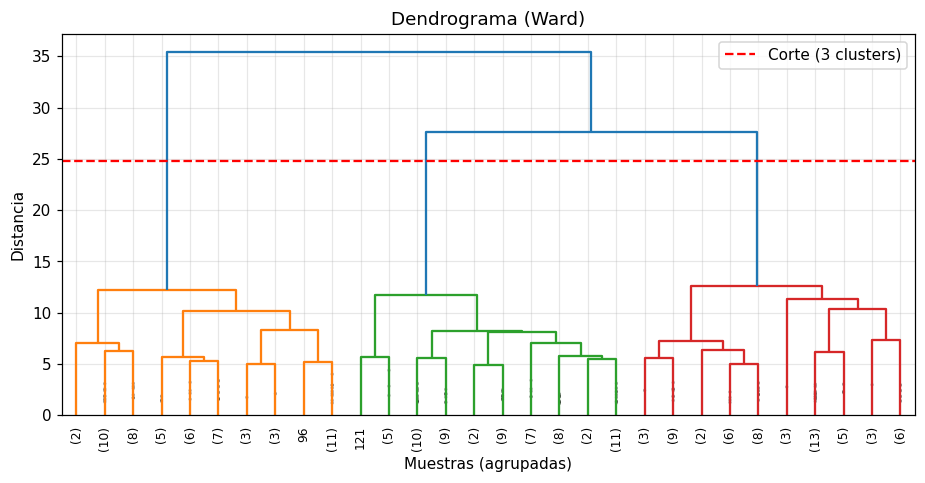

In [7]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 4.5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90,
           leaf_font_size=8, show_contracted=True,
           color_threshold=0.7 * max(Z[:, 2]))
plt.axhline(0.7 * max(Z[:, 2]), color='red', ls='--', label='Corte (3 clusters)')
plt.title('Dendrograma (Ward)')
plt.xlabel('Muestras (agrupadas)'); plt.ylabel('Distancia')
plt.legend()
plt.savefig('figuras/02_dendrograma.png', bbox_inches='tight')
plt.show()

In [8]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_h = agg.fit_predict(X_scaled)

sil_h = silhouette_score(X_scaled, labels_h)
ari_h = adjusted_rand_score(y_real, labels_h)
print(f'Jerárquico (Ward, 3 clusters)  ->  Silueta: {sil_h:.3f} | ARI: {ari_h:.3f}')
print('Tamaño de cada cluster:', np.bincount(labels_h))

Jerárquico (Ward, 3 clusters)  ->  Silueta: 0.277 | ARI: 0.790
Tamaño de cada cluster: [58 56 64]


## 4. Reducción de dimensionalidad con PCA

PCA proyecta los datos sobre nuevos ejes (componentes principales) ortogonales que capturan la máxima varianza. Se revisa cuánta varianza explica cada componente para decidir cuántas conservar.

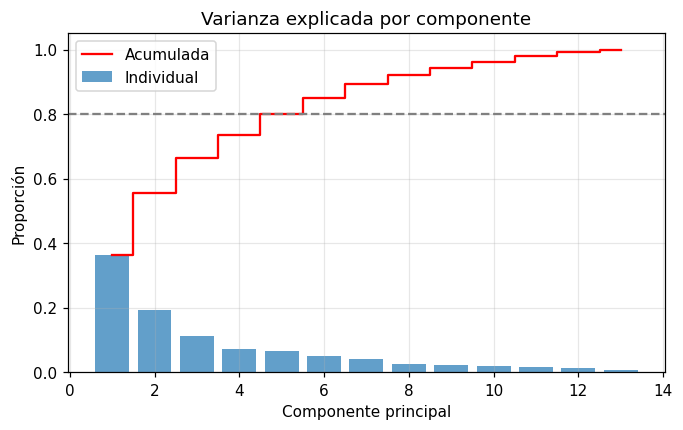

Varianza explicada PC1, PC2, PC3: [0.362 0.192 0.111]
Con 2 componentes: 55.4% | con 3: 66.5% | con 5: 80.2%
Componentes para ≥80% de varianza: 5


In [9]:
pca_full = PCA().fit(X_scaled)
var = pca_full.explained_variance_ratio_
acum = np.cumsum(var)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, 14), var, alpha=0.7, label='Individual')
ax.step(range(1, 14), acum, where='mid', color='red', label='Acumulada')
ax.axhline(0.8, color='gray', ls='--')
ax.set(title='Varianza explicada por componente', xlabel='Componente principal', ylabel='Proporción')
ax.legend()
plt.savefig('figuras/03_varianza_pca.png', bbox_inches='tight')
plt.show()

print('Varianza explicada PC1, PC2, PC3:', var[:3].round(3))
print(f'Con 2 componentes: {acum[1]:.1%} | con 3: {acum[2]:.1%} | con 5: {acum[4]:.1%}')
print('Componentes para ≥80% de varianza:', int(np.argmax(acum >= 0.8) + 1))

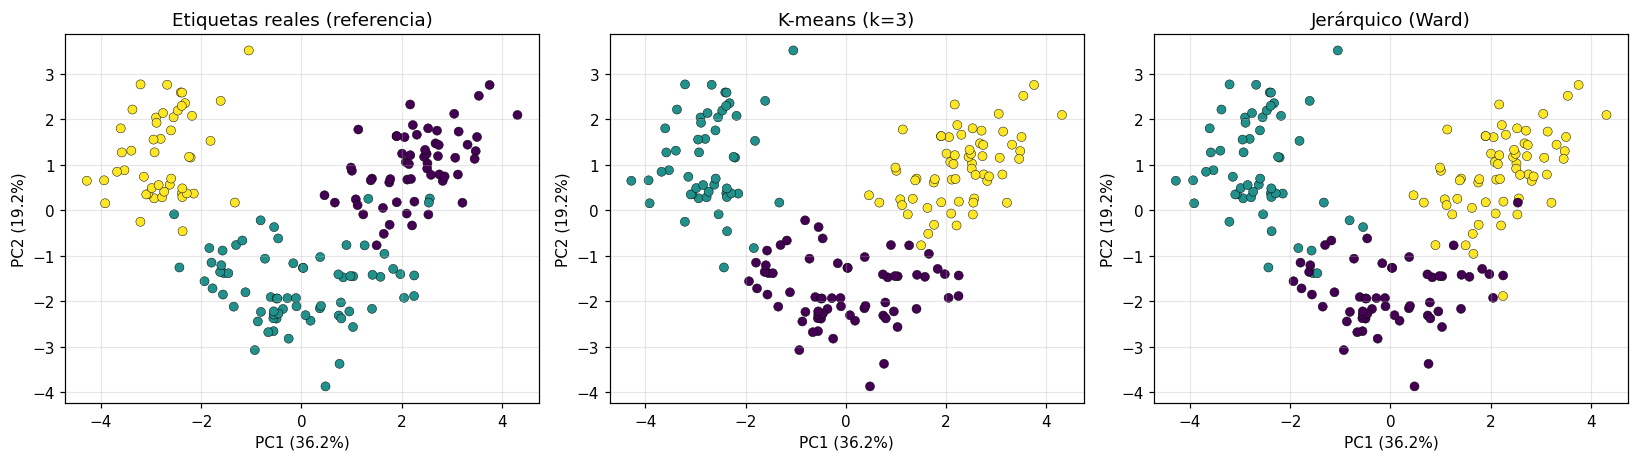

In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, lab, tit in zip(ax, [y_real, labels_km, labels_h],
                       ['Etiquetas reales (referencia)', 'K-means (k=3)', 'Jerárquico (Ward)']):
    sc = a.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap='viridis', s=35, edgecolor='k', linewidth=0.3)
    a.set(title=tit, xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
          ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.tight_layout()
plt.savefig('figuras/04_pca_clusters.png', bbox_inches='tight')
plt.show()

In [11]:
# Qué variables pesan más en cada componente (cargas)
cargas = pd.DataFrame(pca.components_.T, index=X.columns, columns=['PC1', 'PC2']).round(3)
cargas.reindex(cargas['PC1'].abs().sort_values(ascending=False).index)

,PC1,PC2
flavanoids,0.423,-0.003
total_phenols,0.395,0.065
od280/od315_of_diluted_wines,0.376,-0.164
proanthocyanins,0.313,0.039
nonflavanoid_phenols,-0.299,0.029
hue,0.297,-0.279
proline,0.287,0.365
malic_acid,-0.245,0.225
alcalinity_of_ash,-0.239,-0.011
alcohol,0.144,0.484


## 5. Reducción de dimensionalidad con SVD

La **SVD** factoriza la matriz como $X = U \Sigma V^T$. Si los datos están centrados (como tras estandarizar), la SVD y el PCA son equivalentes: los vectores singulares derechos $V$ son las componentes principales y los valores singulares se relacionan con la varianza por $\lambda_i = \sigma_i^2/(n-1)$.

In [12]:
# SVD "a mano" con NumPy
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
var_svd = S**2 / (X_scaled.shape[0] - 1)
ratio_svd = var_svd / var_svd.sum()

print('Valores singulares (primeros 5):', S[:5].round(2))
print('Varianza explicada vía SVD  :', ratio_svd[:3].round(4))
print('Varianza explicada vía PCA  :', var[:3].round(4))
print('¿Coinciden?', np.allclose(ratio_svd, var))

Valores singulares (primeros 5): [28.94 21.08 16.04 12.79 12.32]
Varianza explicada vía SVD  : [0.362  0.1921 0.1112]
Varianza explicada vía PCA  : [0.362  0.1921 0.1112]
¿Coinciden? True


Proyección SVD ≈ PCA (salvo signo): True


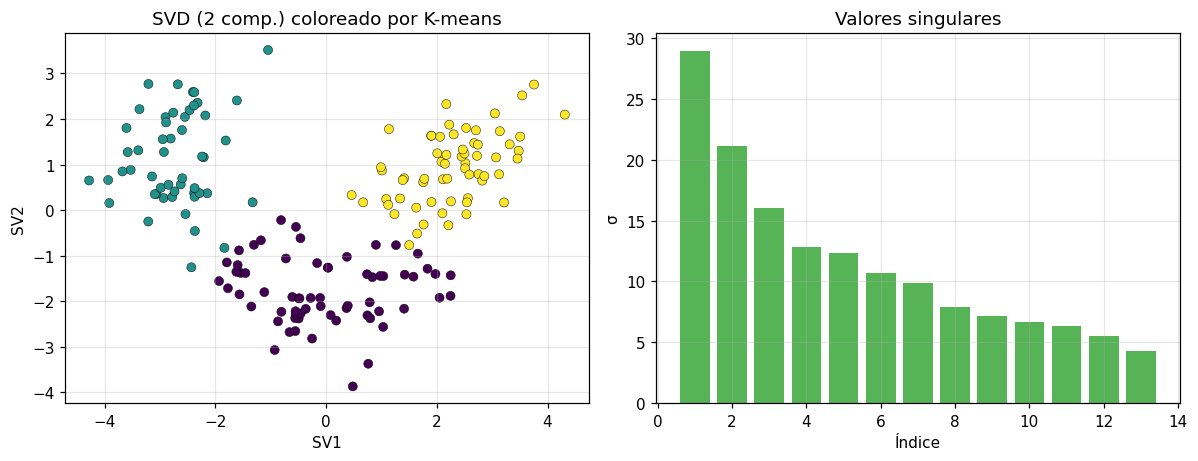

In [13]:
# SVD truncada de Scikit-Learn (2 componentes)
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

# Las proyecciones coinciden con las de PCA salvo por el signo de cada eje
print('Proyección SVD ≈ PCA (salvo signo):',
      np.allclose(np.abs(X_svd), np.abs(X_pca), atol=1e-4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].scatter(X_svd[:, 0], X_svd[:, 1], c=labels_km, cmap='viridis', s=35, edgecolor='k', linewidth=0.3)
ax[0].set(title='SVD (2 comp.) coloreado por K-means', xlabel='SV1', ylabel='SV2')
ax[1].bar(range(1, 14), S, alpha=0.8, color='tab:green')
ax[1].set(title='Valores singulares', xlabel='Índice', ylabel='σ')
plt.tight_layout()
plt.savefig('figuras/05_svd.png', bbox_inches='tight')
plt.show()

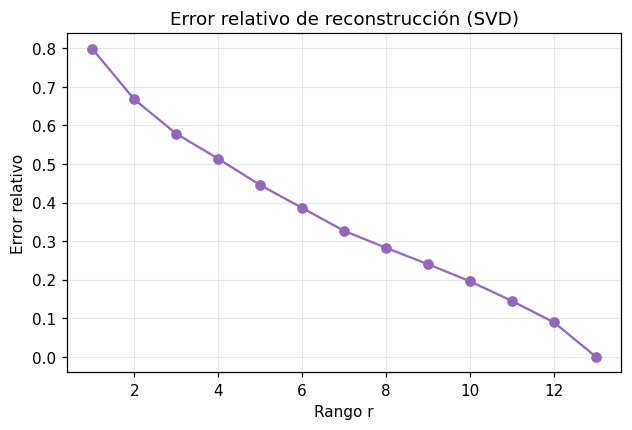

r=2: error relativo = 0.668
r=3: error relativo = 0.579
r=5: error relativo = 0.445
r=8: error relativo = 0.283


In [14]:
# Error de reconstrucción según el número de componentes (SVD)
errores = []
for r in range(1, 14):
    X_rec = (U[:, :r] * S[:r]) @ Vt[:r, :]
    errores.append(np.linalg.norm(X_scaled - X_rec) / np.linalg.norm(X_scaled))

plt.figure(figsize=(6.5, 4))
plt.plot(range(1, 14), errores, 'o-', color='tab:purple')
plt.title('Error relativo de reconstrucción (SVD)')
plt.xlabel('Rango r'); plt.ylabel('Error relativo')
plt.savefig('figuras/06_reconstruccion.png', bbox_inches='tight')
plt.show()

for r in (2, 3, 5, 8):
    print(f'r={r}: error relativo = {errores[r-1]:.3f}')

## 6. Clustering después de reducir dimensionalidad

Se repite K-means sobre las 2 y 5 primeras componentes de PCA para ver si se pierde estructura al comprimir los datos.

In [15]:
resultados = []
resultados.append(['Original (13 vars)', silhouette_score(X_scaled, labels_km), ari_km])

for n in (2, 5):
    Xr = PCA(n_components=n).fit_transform(X_scaled)
    lab = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xr)
    resultados.append([f'PCA {n} comp.', silhouette_score(Xr, lab), adjusted_rand_score(y_real, lab)])

tabla = pd.DataFrame(resultados, columns=['Datos usados en K-means', 'Silueta', 'ARI']).round(3)
tabla

,Datos usados en K-means,Silueta,ARI
0,Original (13 vars),0.285,0.897
1,PCA 2 comp.,0.561,0.895
2,PCA 5 comp.,0.369,0.897


In [16]:
# Resumen general de métodos
resumen = pd.DataFrame({
    'Método': ['K-means', 'Jerárquico (Ward)'],
    'Silueta': [sil_km, sil_h],
    'ARI': [ari_km, ari_h],
}).round(3)
resumen

,Método,Silueta,ARI
0,K-means,0.285,0.897
1,Jerárquico (Ward),0.277,0.790


## 7. Conclusiones

- La **estandarización** fue necesaria por las diferentes escalas de las variables.
- Silueta y codo coinciden en **k = 3**, que además corresponde a los 3 cultivares reales.
- **K-means** recupera casi por completo la estructura real (ARI = 0.897); el **clustering jerárquico (Ward)** también la recupera bien, aunque algo peor (ARI = 0.790).
- **PCA** con 2 componentes retiene aproximadamente el 55 % de la varianza y ya permite visualizar tres grupos bien diferenciados; con 5 componentes se supera el 80 %.
- **SVD y PCA** son equivalentes sobre datos centrados; la SVD permite además analizar la reconstrucción de la matriz.
- Comprimir los datos con PCA no degrada el clustering (ARI ≈ 0.90 con 2 y 5 componentes). La silueta sube a 0.561 con 2 componentes, pero no es comparable con la de 13 variables porque se calcula en otro espacio.